Shape: (9551, 21)
Aggregate rating        0
Cuisines                9
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Votes                   0
Average Cost for two    0
Price range             0
Longitude               0
Latitude                0
Country Code            0
dtype: int64
Removed 2148 unrated rows. Remaining: 7403
Final data: (7403, 10)
Train: (5922, 10) Test: (1481, 10)
            Model    MSE   RMSE    MAE     R2
    Random Forest 0.1154 0.3397 0.2531 0.6268
    Decision Tree 0.1416 0.3763 0.2787 0.5422
Linear Regression 0.1856 0.4308 0.3397 0.3999
Best model: Random Forest


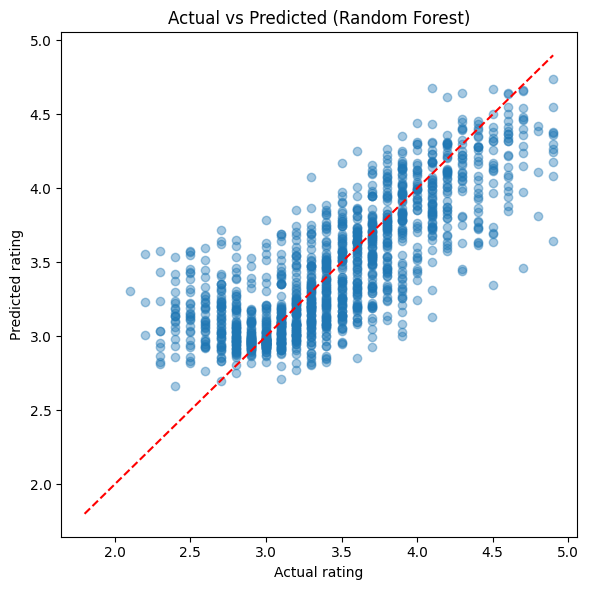

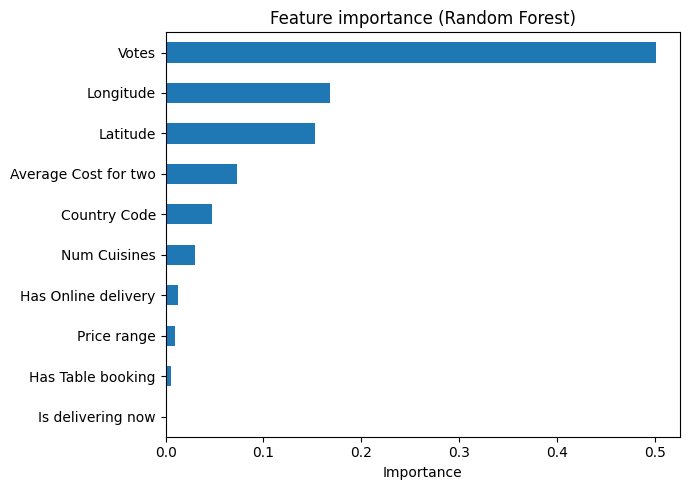

Votes                   0.500659
Longitude               0.167936
Latitude                0.152584
Average Cost for two    0.072899
Country Code            0.047266
Num Cuisines            0.030169
Has Online delivery     0.012435
Price range             0.009308
Has Table booking       0.005346
Is delivering now       0.001398
dtype: float64
Saved results to /Users/adiyy/Documents/Cognifyz_INTERNSHIP/Task_1_Rating_Prediction/outputs


In [14]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42

# ---------- Load data ----------
DATA_PATH = Path("..") / "Dataset .csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH.resolve()}")
if DATA_PATH.stat().st_size == 0:
    raise ValueError("Dataset file is empty. Copy the real file again.")

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
print("Shape:", df.shape)

# ---------- Validate columns ----------
TARGET = "Aggregate rating"
YES_NO_COLS = ["Has Table booking", "Has Online delivery", "Is delivering now"]
NUMERIC_COLS = [
    "Votes",
    "Average Cost for two",
    "Price range",
    "Longitude",
    "Latitude",
    "Country Code",
]
REQUIRED = [TARGET, "Cuisines"] + YES_NO_COLS + NUMERIC_COLS

missing_cols = [c for c in REQUIRED if c not in df.columns]
if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}")

print(df[REQUIRED].isnull().sum())

# ---------- Clean ----------
df = df.drop_duplicates().copy()

before = len(df)
df = df[df[TARGET] > 0].copy()  # 0.0 means "not rated"
print(f"Removed {before - len(df)} unrated rows. Remaining: {len(df)}")

df = df[df[TARGET].between(0, 5)].copy()

# ---------- Encode / engineer features ----------
for col in YES_NO_COLS:
    df[col] = df[col].astype(str).str.strip().str.title().map({"Yes": 1, "No": 0})
    if df[col].isnull().any():
        raise ValueError(f"Unexpected values in column '{col}'")


def count_cuisines(value):
    if pd.isnull(value) or str(value).strip() == "":
        return 0
    return len([c for c in str(value).split(",") if c.strip()])


df["Num Cuisines"] = df["Cuisines"].apply(count_cuisines)

for col in NUMERIC_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

FEATURES = NUMERIC_COLS + YES_NO_COLS + ["Num Cuisines"]
df = df.dropna(subset=FEATURES + [TARGET]).copy()

X = df[FEATURES]
y = df[TARGET]
print("Final data:", X.shape)

# ---------- Split ----------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)

# ---------- Train and evaluate ----------
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    mse = mean_squared_error(y_test, pred)
    results.append(
        {
            "Model": name,
            "MSE": round(mse, 4),
            "RMSE": round(float(np.sqrt(mse)), 4),
            "MAE": round(mean_absolute_error(y_test, pred), 4),
            "R2": round(r2_score(y_test, pred), 4),
        }
    )

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print(results_df.to_string(index=False))

best_name = results_df.iloc[0]["Model"]
print("Best model:", best_name)

# ---------- Plots ----------
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions[best_name], alpha=0.4)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual rating")
plt.ylabel("Predicted rating")
plt.title(f"Actual vs Predicted ({best_name})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "actual_vs_predicted.png", dpi=150)
plt.show()

rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()

plt.figure(figsize=(7, 5))
importance.plot(kind="barh")
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=150)
plt.show()

print(importance.sort_values(ascending=False))

results_df.to_csv(OUTPUT_DIR / "model_results.csv", index=False)
print("Saved results to", OUTPUT_DIR.resolve())